# Notebook 03: Product-Level Assortment & Pricing Analytics
**Course:** 23CSE452 Business Analytics Capstone — Review 2  
**Objective:** Analyze the distribution of selling prices, MRP compliance, and discount depths across all 609 scraped Blinkit SKUs to evaluate dark store promotional dynamics.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_path = '../data/processed/product_catalogue/cleaned_product_catalogue.csv'
if not os.path.exists(csv_path):
    csv_path = '../../data_pipeline/cleaned_product_catalogue.csv'
df = pd.read_csv(csv_path)
print('Loaded', len(df), 'SKUs.')

Loaded 609 SKUs.


## 1. Selling Price Dispersion by Category (Boxplot)

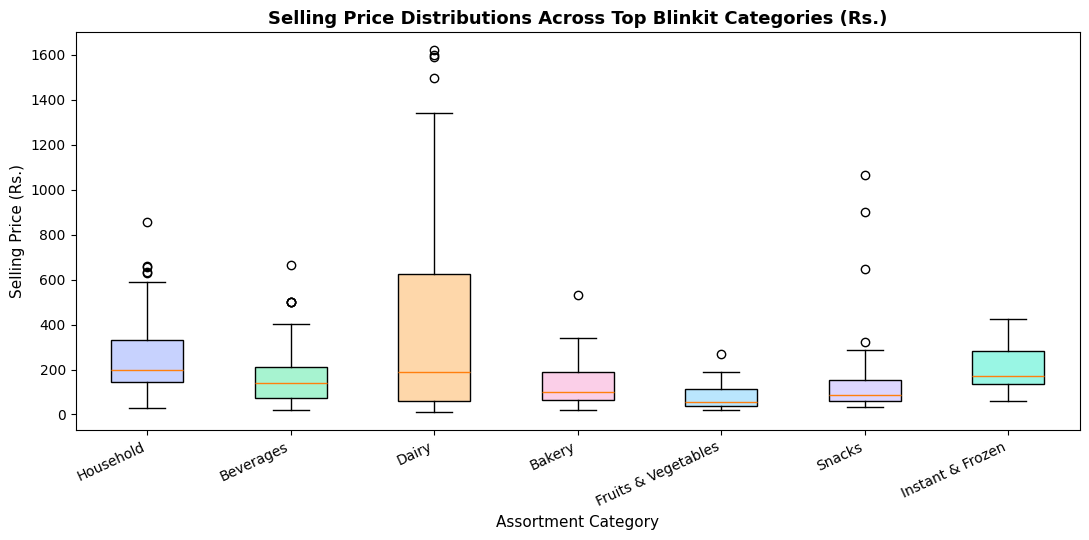

In [2]:
top_cats = df['category'].value_counts().head(7).index.tolist()
cat_data = [df[df['category'] == c]['displayed_price'].dropna().values for c in top_cats]

plt.figure(figsize=(11, 5.5))
box = plt.boxplot(cat_data, patch_artist=True, tick_labels=top_cats)
colors = ['#c7d2fe', '#a7f3d0', '#fed7aa', '#fbcfe8', '#bae6fd', '#ddd6fe', '#99f6e4']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
plt.title('Selling Price Distributions Across Top Blinkit Categories (Rs.)', fontsize=13, fontweight='bold')
plt.xlabel('Assortment Category', fontsize=11)
plt.ylabel('Selling Price (Rs.)', fontsize=11)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 2. Promotional Discount Depth Analysis

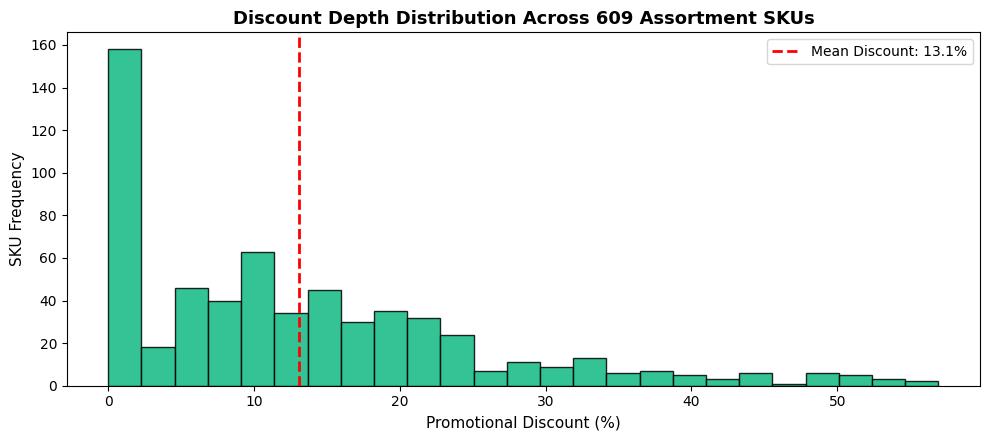

In [3]:
plt.figure(figsize=(10, 4.5))
plt.hist(df['discount_pct'], bins=25, color='#10b981', edgecolor='black', alpha=0.85)
plt.axvline(df['discount_pct'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean Discount: {df["discount_pct"].mean():.1f}%')
plt.title('Discount Depth Distribution Across 609 Assortment SKUs', fontsize=13, fontweight='bold')
plt.xlabel('Promotional Discount (%)', fontsize=11)
plt.ylabel('SKU Frequency', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

## 3. High-Discount vs Staple Category Comparison

In [4]:
cat_summary = df.groupby('category').agg(
    sku_count=('source_product_id', 'count'),
    avg_mrp=('original_price', 'mean'),
    avg_price=('displayed_price', 'mean'),
    avg_discount=('discount_pct', 'mean')
).sort_values('sku_count', ascending=False)

print('Assortment Category Summary:')
cat_summary.round(2)

Assortment Category Summary:


,sku_count,avg_mrp,avg_price,avg_discount
category,,,,
Household,100,314.16,250.69,18.84
Beverages,88,182.42,161.09,10.74
Dairy,83,404.05,377.58,4.12
Bakery,70,134.51,129.77,2.42
Fruits & Vegetables,68,96.71,78.56,18.13
Snacks,67,156.63,139.06,11.17
Instant & Frozen,61,239.67,204.38,14.56
Personal Care,37,450.73,369.92,18.19
Staples,35,474.97,329.91,31.32
